# Forecasting data analysis

This notebook analyzes the current v3 source and reproduces the processing stages in memory using the pipeline functions. Run from `Data/forecasting-data`; it does not overwrite pipeline artifacts. Counts are sequential where indicated, and the coordinate box is a coarse geographic filter, not an administrative boundary.


In [1]:
from pathlib import Path
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

root = Path.cwd()
if not (root / "step-1").is_dir():
    raise RuntimeError("Run this notebook from Data/forecasting-data.")

def load_stage(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(module)
    return module

step1 = load_stage("forecast_step1", root / "step-1/remove-unreliable-features.py")
step2 = load_stage("forecast_step2", root / "step-2/data-cleanup.py")
step3 = load_stage("forecast_step3", root / "step-3/data-finalize.py")
raw = pd.read_csv(step1.INPUT_FILE, dtype={"listing_id": "string"})
selected = step1.build_reliable_dataset(raw)
print(f"Source: {step1.INPUT_FILE}\nRaw records: {len(raw):,}; Step 1 records: {len(selected):,}")


Source: /Users/macos/Data/Master/hocky3/Kỹ thuật xử lý dữ liệu/IT2047/Data/v3/master_v3.csv
Raw records: 6,703; Step 1 records: 6,703


/var/folders/d6/jyng8vc51s37b5434bk1wqw00000gn/T/ipykernel_26890/2982171810.py:21: DtypeWarning: Columns (16,154,241,247,248) have mixed types. Specify dtype option on import or set low_memory=False.
  raw = pd.read_csv(step1.INPUT_FILE, dtype={"listing_id": "string"})


## Raw source and normalized categories

Step 1 selects features and normalizes property type and legal status. Counts below describe the same records before and after normalization.


In [2]:
print("Raw property types:")
display(raw["property_type"].value_counts(dropna=False).to_frame("count"))
print("Normalized property types and legal status:")
display(selected["property_type"].value_counts(dropna=False).to_frame("count"))
display(selected["legal_status"].value_counts(dropna=False).to_frame("count"))


Raw property types:


,count
property_type,
Nhà đất,2382
Nhà riêng,1716
Căn hộ chung cư,1127
Nhà mặt phố,609
Căn hộ,464
"Nhà biệt thự, liền kề",323
"Shophouse, nhà phố thương mại",82


Normalized property types and legal status:


,count
property_type,
Nhà đất,5112
Căn hộ,1591


,count
legal_status,
Sổ hồng riêng,6046
Hợp đồng mua bán,217
Sổ chung,217
Đang chờ sổ,134
Không rõ,89


## Step 2: sequential cleaning

Each removal count is relative to the preceding stage. Missing or nonnumeric coordinates also fail the bounding-box check.


In [3]:
duplicates = selected.loc[selected["listing_id"].duplicated(keep=False)].sort_values("listing_id")
print(f"Duplicate ID values: {duplicates['listing_id'].nunique():,}; rows involved: {len(duplicates):,}")
display(duplicates.head())
unique = step2.duplicate_records_filter(selected)
coordinates = step2.coordinates_filter(unique)
complete = step2.bedrooms_filter(coordinates)
cleaned = step2.remove_furnishing(complete)
display(pd.DataFrame({"stage": ["Step 1", "Deduplicated", "Valid coordinates", "Bedrooms present"],
                      "rows": [len(selected), len(unique), len(coordinates), len(cleaned)]}))
print(f"Removed: {len(selected)-len(unique):,} duplicates, {len(unique)-len(coordinates):,} invalid coordinates, {len(coordinates)-len(complete):,} missing bedrooms.")
display(cleaned.isna().sum().rename("missing").to_frame())


Duplicate ID values: 0; rows involved: 0


,listing_id,property_type,area,latitude,longitude,district,bedrooms,legal_status,furnishing,price_range


,stage,rows
0,Step 1,6703
1,Deduplicated,6703
2,Valid coordinates,6676
3,Bedrooms present,5872


Removed: 0 duplicates, 27 invalid coordinates, 804 missing bedrooms.


,missing
listing_id,0
property_type,0
area,1
latitude,0
longitude,0
district,0
bedrooms,0
legal_status,0
price_range,95


## Step 3: outlier rules and resulting data

The rules and filtering function are imported directly from the training pipeline. Unit price is in million VND/m²; price is in billion VND.


In [4]:
display(pd.DataFrame({"Căn hộ": step3.APARTMENT_RULES, "Nhà đất": step3.HOUSE_RULES}))
final, apt_dropped, house_dropped = step3.remove_outliers(cleaned)
print(f"Step 2: {len(cleaned):,}; Step 3: {len(final):,}; removed apartments: {apt_dropped:,}; houses/land: {house_dropped:,}.")
print("Other or missing property types are excluded by the Step 3 split:",
      len(cleaned) - cleaned["property_type"].isin(["Căn hộ", "Nhà đất"]).sum())
display(final.groupby("property_type")[["area", "bedrooms", "price_range"]].agg(["count", "median", "min", "max"]))


,Căn hộ,Nhà đất
min_area,25.0,20.0
max_area,150.0,350.0
min_beds,1.0,1.0
max_beds,4.0,8.0
min_price,1.0,1.5
max_price,20.0,40.0
min_price_m2,20.0,30.0
max_price_m2,180.0,350.0


Step 2: 5,872; Step 3: 5,009; removed apartments: 162; houses/land: 701.
Other or missing property types are excluded by the Step 3 split: 0


area                     bedrooms                  price_range  \
              count median   min    max    count median  min  max       count   
property_type                                                                   
Căn hộ         1395   68.8  26.0  150.0     1395    2.0  1.0  4.0        1395   
Nhà đất        3614   62.2  20.0  343.5     3614    4.0  1.0  8.0        3614   

                                 
              median  min   max  
property_type                    
Căn hộ          3.79  1.0  20.0  
Nhà đất         7.59  1.5  40.0

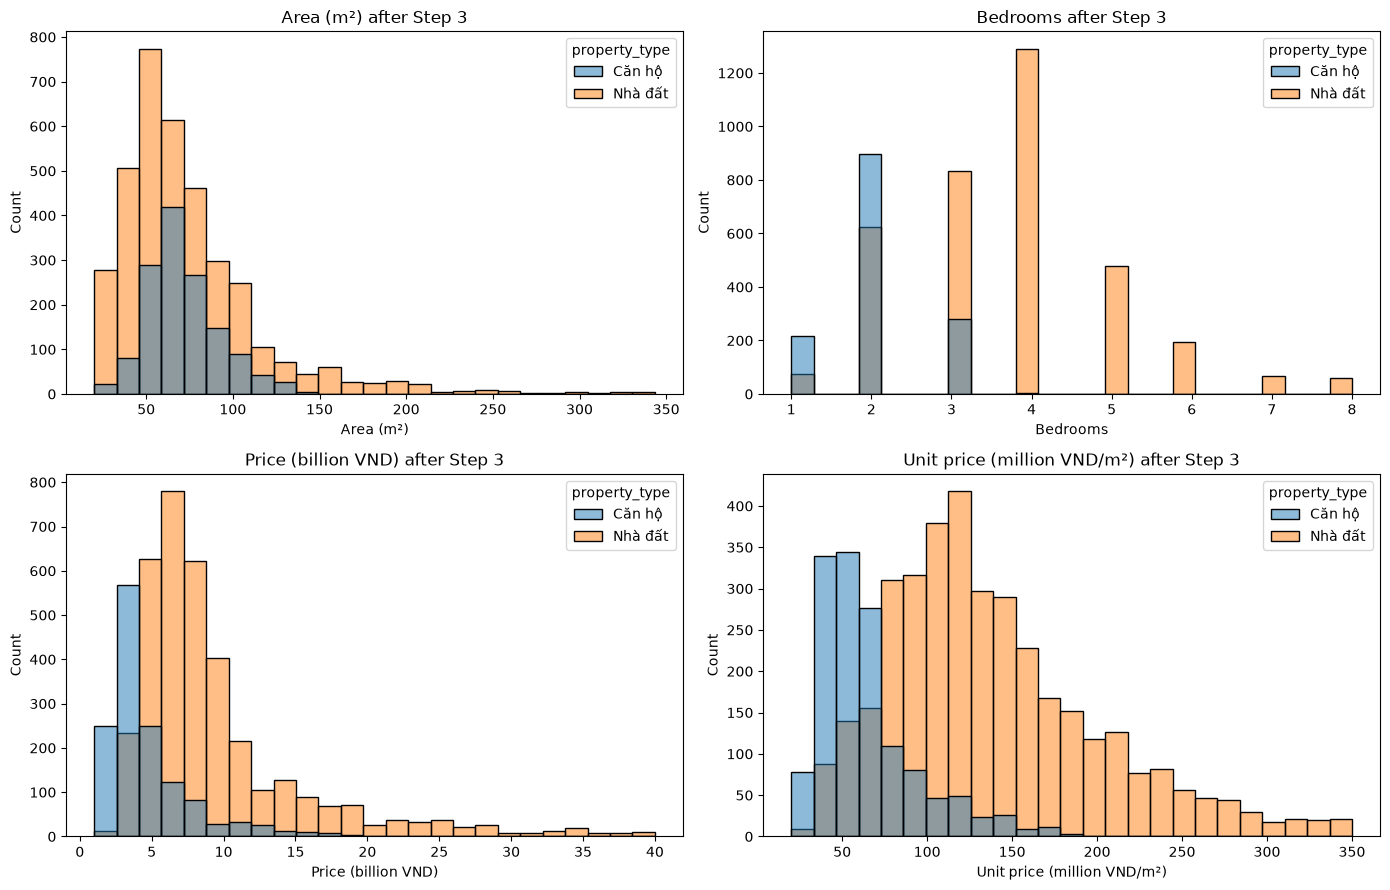

In [5]:
plot_data = final.copy()
plot_data["price_per_m2"] = plot_data["price_range"] * 1000 / plot_data["area"]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, col, label in zip(axes.flat, ["area", "bedrooms", "price_range", "price_per_m2"],
                          ["Area (m²)", "Bedrooms", "Price (billion VND)", "Unit price (million VND/m²)"]):
    sns.histplot(data=plot_data, x=col, hue="property_type", bins=25, ax=ax)
    ax.set_xlabel(label)
    ax.set_title(label + " after Step 3")
plt.tight_layout()
plt.show()


## Model-ready data

Step 4 creates `area_per_bedroom`, transforms price to `log_price`, and one-hot encodes categories. The summary below describes the checked-in Step 4 artifact; rerun the pipeline if the source has changed.


In [6]:
encoded = pd.read_excel(root / "step-4/encoded_data.xlsx", dtype={"listing_id": "string"})
print(f"Checked-in encoded artifact: {len(encoded):,} rows, {len(encoded.columns):,} columns")
print("Rows in in-memory Step 3:", len(final))
print("Columns:", list(encoded.columns))


Checked-in encoded artifact: 5,009 rows, 131 columns
Rows in in-memory Step 3: 5009
Columns: ['listing_id', 'area', 'bedrooms', 'area_per_bedroom', 'latitude', 'longitude', 'property_type_Căn hộ', 'property_type_Nhà đất', 'legal_status_Hợp đồng mua bán', 'legal_status_Không rõ', 'legal_status_Sổ chung', 'legal_status_Sổ hồng riêng', 'legal_status_Đang chờ sổ', 'district_Huyện Bình Chánh', 'district_Phường An Hội Tây', 'district_Phường An Hội Đông', 'district_Phường An Khánh', 'district_Phường An Lạc', 'district_Phường An Nhơn', 'district_Phường An Phú', 'district_Phường An Phú Đông', 'district_Phường An Đông', 'district_Phường Bàn Cờ', 'district_Phường Bình Dương', 'district_Phường Bình Hòa', 'district_Phường Bình Hưng Hòa', 'district_Phường Bình Lợi Trung', 'district_Phường Bình Phú', 'district_Phường Bình Quới', 'district_Phường Bình Thạnh', 'district_Phường Bình Thới', 'district_Phường Bình Tiên', 'district_Phường Bình Trưng', 'district_Phường Bình Trị Đông', 'district_Phường Bình T